# 3 · Training & Evaluasi LSTM: Dengan Augmentasi

Notebook ini sama persis dengan `2_training_tanpa_augmentasi.ipynb`, **kecuali data latihnya ditambah salinan augmentasi** (×3, dari `data/dataset_augmentasi/`). Konfigurasi hyperparameter memakai hasil tuning notebook 2, supaya perbedaan hasil hanya berasal dari augmentasi.

| Bagian | Isi |
|---|---|
| 1 | Setup & konfigurasi |
| 2 | Memuat data (asli + augmentasi) dan membuat 5 skema fitur |
| 3 | Menyiapkan sekuens dan model LSTM |
| 4 | Memuat konfigurasi terbaik dari notebook 2 |
| 5 | Training & evaluasi: holdout + LOSO, baseline, uji urutan diacak |
| 6 | **Hasil per skema**: tabel metrik, learning curve, confusion matrix, laporan per kelas |
| 7 | Ringkasan semua skema |
| 8 | Perbandingan tanpa vs dengan augmentasi |

**Lima skema fitur** (semua dihitung dari CSV Skema A):

| Skema | Fitur per frame | Isi | Yang dipelajari model |
|---|---|---|---|
| A | 52 | 13 keypoints × (x, y, z, visibility) mentah | postur + posisi di gambar + gerakan |
| A' | 26 | (x, y) dipusatkan di pinggul, dibagi panjang badan | postur + gerakan (tanpa posisi di gambar) |
| B | 8 | sudut sendi (Angle Directive Rules) | postur + gerakan |
| C | 16 | sudut − rata-rata sudut per video, + kecepatan sudut | **gerakan saja** |
| D | 52 | koordinat A' − rata-rata per video, + kecepatan | **gerakan saja** |

**Dua cara evaluasi:**
- **Holdout**: latih 8 subjek, validasi subjek 7, uji subjek 1 (24 video).
- **LOSO** (*Leave-One-Subject-Out*): 9 putaran, setiap subjek bergiliran menjadi data uji. Hasilnya dirata-rata, jadi lebih bisa dipercaya daripada holdout yang hanya menguji 1 orang.

Semua hasil disimpan ke `results/dengan_augmentasi/`. Progres training dapat dipantau di terminal: `tail -f results/dengan_augmentasi/progress.log`.

## 1. Setup & Konfigurasi

**💡 Penjelasan kode**

- `TF_NUM_INTRAOP_THREADS = 2`: setiap model TensorFlow memakai 2 thread CPU, sehingga beberapa model bisa dilatih **bersamaan** (paralel) tanpa berebut CPU.
- **joblib** (`Parallel`, `delayed`) menjalankan beberapa training sekaligus di proses terpisah.
- **scikit-learn** (`sklearn`) dipakai untuk menghitung metrik (akurasi, presisi, recall, F1, confusion matrix) dan untuk model baseline (Logistic Regression).

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # sembunyikan log TensorFlow yang tidak penting
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "2")    # 2 thread per model -> beberapa model bisa paralel
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")

import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

**💡 Penjelasan kode**

Semua pengaturan eksperimen ada di sel ini:
- `USE_AUGMENTATION = True`: **satu-satunya perbedaan** antara notebook 2 dan 3.
- `SCHEMES`, `SEQ_MODES`: 5 skema × 2 cara menyamakan panjang video = 10 kombinasi.
- `RESAMPLE_LEN`, `WINDOW_SIZE`, `WINDOW_STRIDE`: pengaturan sekuens (dijelaskan di bagian 3).
- `LSTM1_UNITS ... DENSE_UNITS`: arsitektur model sesuai Gambar 3.3 proposal.
- `BEST_CONFIG_CSV`: konfigurasi terbaik hasil tuning notebook 2.
- `N_JOBS = 5`: jumlah model yang dilatih bersamaan. Kurangi jika laptop terasa berat.
- `QUICK = True`: uji coba cepat (epoch sangat sedikit), hanya untuk mengecek kode tidak error. Untuk hasil akhir harus `False`.
- `log_progress`: menulis progres ke file `progress.log` supaya bisa dipantau dari terminal.

In [2]:
USE_AUGMENTATION = True

# ---------------- Path ----------------
ROOT = Path.cwd()
FEAT_DIR = ROOT / "data" / "features"                 # dataset tanpa augmentasi (CSV Skema A)
AUG_DIR = ROOT / "data" / "dataset_augmentasi"        # dataset dengan augmentasi (asli + aug1 + aug2)
SPLITS_JSON = ROOT / "data" / "splits.json"
OUT_DIR = ROOT / "results" / ("dengan_augmentasi" if USE_AUGMENTATION else "tanpa_augmentasi")
FIG_DIR, MODEL_DIR = OUT_DIR / "figures", OUT_DIR / "models"
for d in (OUT_DIR, FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
CLASS_NAMES = ["Lat_Pulldown", "Seated_Cable_Row", "Bent_over"]  # label 0, 1, 2
SHORT_NAMES = ["Lat Pulldown", "Seated Row", "Bent Over"]
TARGET_W, TARGET_H = 720, 1280                                   # resolusi saat ekstraksi keypoints

# ---------------- Skema & sekuens ----------------
SCHEMES = ["A", "A'", "B", "C", "D"]
SEQ_MODES = ["resample", "window"]
RESAMPLE_LEN = 60                   # mode resample: 1 video -> tepat 60 frame
WINDOW_SIZE, WINDOW_STRIDE = 30, 10 # mode window: potongan 30 frame, digeser 10 frame

# ---------------- Arsitektur (Gambar 3.3) ----------------
LSTM1_UNITS, LSTM2_UNITS, DROPOUT, DENSE_UNITS = 64, 32, 0.3, 32

# ---------------- Hyperparameter ----------------
BEST_CONFIG_CSV = ROOT / 'results' / 'tanpa_augmentasi' / 'best_config.csv'  # hasil tuning notebook 2

N_JOBS = 5      # jumlah model yang dilatih bersamaan
QUICK = False   # True = uji coba cepat; hasil akhir harus False

PROGRESS_LOG = OUT_DIR / "progress.log"
PROGRESS_LOG.write_text("")
_T0 = time.time()


def log_progress(stage, done, total, info=""):
    pct = done / total
    bar = "#" * int(pct * 20) + "-" * (20 - int(pct * 20))
    with open(PROGRESS_LOG, "a") as f:
        f.write(f"[{time.strftime('%H:%M:%S')}] {stage:8s} [{bar}] {done}/{total} ({pct:.0%}) {info} "
                f"| berjalan {(time.time() - _T0) / 60:.1f} menit\n")

## 2. Memuat Data & Membuat Skema Fitur

Semua skema dihitung dari **satu sumber**: CSV Skema A (13 keypoints × x, y, z, visibility per frame).
Untuk notebook ini, setiap video punya 3 versi dari `data/dataset_augmentasi/`: `_asli`, `_aug1`, `_aug2`.

**💡 Penjelasan kode**

- `index`: daftar semua video (label, subjek, lokasi file). Video `excluded` dibuang.
- `splits`: pembagian subjek untuk holdout dan LOSO dari `1_preprocessing.ipynb`.
- `load_keypoints(path)`: membaca CSV lalu mengubah bentuknya menjadi array **(T, 13, 4)**: T frame × 13 titik × 4 nilai.
- `RAW[video_id]`: daftar versi keypoints tiap video. Di notebook ini isinya 3 versi: `[asli, aug1, aug2]`. Versi pertama selalu data asli, dan hanya versi ini yang dipakai untuk validasi dan uji.

In [3]:
index = pd.read_csv(FEAT_DIR / "index.csv")
index = index[~index.excluded].reset_index(drop=True)
splits = json.loads(SPLITS_JSON.read_text())
LABEL = dict(zip(index.video_id, index.label))


def load_keypoints(path):
    # CSV format Skema A -> (T, 13, 4): x, y, z, visibility
    return pd.read_csv(path).drop(columns="frame").to_numpy(np.float32).reshape(-1, 13, 4)


aug_index = pd.read_csv(AUG_DIR / "index.csv")
RAW = {}  # video_id -> [asli, aug1, aug2]
for vid, g in aug_index.groupby("video_id"):
    g = g.set_index("salinan").loc[["asli", "aug1", "aug2"]]
    RAW[vid] = [load_keypoints(AUG_DIR / p) for p in g.path]
RAW = {v: RAW[v] for v in index.video_id}

print(f"{len(RAW)} video × {len(next(iter(RAW.values())))} versi (asli + augmentasi)")
print("Holdout:", {k: v["subjects"] for k, v in splits["holdout"].items()})

240 video × 3 versi (asli + augmentasi)
Holdout: {'train': [2, 3, 4, 5, 6, 8, 9, 10], 'val': [7], 'test': [1]}


**💡 Penjelasan kode**

Di sini kelima skema dibuat dari keypoints:
- `pixel_xy`: x dan y MediaPipe bernilai 0–1 relatif terhadap lebar (720) dan tinggi (1280). Keduanya dikali ke piksel supaya jarak dan sudut tidak "gepeng".
- `centered_xy` (**A'**): setiap frame digeser supaya tengah pinggul berada di (0, 0), lalu dibagi panjang badan (jarak bahu–pinggul). Hasilnya tidak bergantung pada posisi orang di gambar maupun jarak kamera.
- `joint_angles` (**B**): 8 sudut sendi dengan `arctan2`, rumus yang sama dengan preprocessing.
- `velocity`: selisih nilai frame ini dengan frame sebelumnya, yaitu **kecepatan** perubahan.
- **C** = sudut − rata-rata sudut dalam video (postur dasar hilang, tinggal perubahannya) + kecepatan sudut.
- **D** = koordinat A' − rata-rata dalam video + kecepatan koordinat.
- `FEATURES[skema][video_id]`: daftar array fitur (T, jumlah fitur) untuk setiap versi video.
- Baris terakhir mengecek bahwa sudut Skema B di sini **sama** dengan CSV Skema B dari preprocessing.

In [4]:
# 8 sudut sendi (Tabel 3.3) dalam indeks 13 keypoints: (A, B, C), B = sendi yang diukur
# 0 nose, 1/2 bahu kiri/kanan, 3/4 siku, 5/6 pergelangan tangan, 7/8 pinggul, 9/10 lutut, 11/12 pergelangan kaki
ANGLE_TRIPLETS = [(7, 1, 3), (8, 2, 4), (1, 3, 5), (2, 4, 6), (1, 7, 9), (2, 8, 10), (7, 9, 11), (8, 10, 12)]


def pixel_xy(raw):
    return raw[..., :2] * np.array([TARGET_W, TARGET_H], np.float32)


def centered_xy(raw):
    xy = pixel_xy(raw)
    hip = xy[:, [7, 8]].mean(1, keepdims=True)            # tengah pinggul tiap frame
    shoulder = xy[:, [1, 2]].mean(1, keepdims=True)       # tengah bahu tiap frame
    torso = np.median(np.linalg.norm(shoulder - hip, axis=-1))
    return ((xy - hip) / torso).reshape(len(raw), -1)     # (T, 26): x0, y0, x1, y1, ...


def joint_angles(raw):
    xy = pixel_xy(raw)
    out = np.empty((len(raw), len(ANGLE_TRIPLETS)), np.float32)
    for j, (a, b, c) in enumerate(ANGLE_TRIPLETS):
        ba, bc = xy[:, a] - xy[:, b], xy[:, c] - xy[:, b]
        deg = np.abs(np.degrees(np.arctan2(bc[:, 1], bc[:, 0]) - np.arctan2(ba[:, 1], ba[:, 0]))) % 360
        out[:, j] = np.where(deg > 180, 360 - deg, deg)
    return out


def velocity(f):
    return np.diff(f, axis=0, prepend=f[:1])


def make_features(scheme, raw):
    if scheme == "A":
        return raw.reshape(len(raw), -1)
    if scheme == "A'":
        return centered_xy(raw)
    if scheme == "B":
        return joint_angles(raw)
    if scheme == "C":
        a = joint_angles(raw)
        return np.concatenate([a - a.mean(0), velocity(a)], axis=1)
    if scheme == "D":
        xy = centered_xy(raw)
        return np.concatenate([xy - xy.mean(0), velocity(xy)], axis=1)
    raise ValueError(scheme)


FEATURES = {s: {v: [make_features(s, r).astype(np.float32) for r in versions] for v, versions in RAW.items()}
            for s in SCHEMES}

for s in SCHEMES:
    print(f"Skema {s:2s}: {FEATURES[s][index.video_id[0]][0].shape[1]:2d} fitur per frame")
r0 = index.iloc[0]
diff = np.abs(FEATURES["B"][r0.video_id][0] - pd.read_csv(FEAT_DIR / r0.schemeB_path).drop(columns="frame").to_numpy()).max()
print(f"Cek Skema B vs CSV preprocessing: selisih maksimum {diff:.4f}°")

Skema A : 52 fitur per frame
Skema A': 26 fitur per frame
Skema B :  8 fitur per frame
Skema C : 16 fitur per frame
Skema D : 52 fitur per frame
Cek Skema B vs CSV preprocessing: selisih maksimum 0.0138°


## 3. Sekuens & Model LSTM

Durasi video berbeda-beda, padahal LSTM butuh input dengan panjang yang sama. Ada dua cara:

- **resample**: setiap video "diregangkan/dipadatkan" menjadi tepat 60 frame. 1 video = 1 sampel = 1 repetisi utuh.
- **window**: potongan 30 frame digeser setiap 10 frame di dalam satu video. 1 video = beberapa sampel. Prediksi per video = rata-rata prediksi semua potongannya.

Semua metrik dihitung **per video**, supaya kedua mode bisa dibandingkan langsung.

**💡 Penjelasan kode**

- `to_samples(seq, mode)`: mengubah satu video menjadi sampel. Mode resample memakai `np.interp` (interpolasi) ke 60 titik waktu; mode window memotong-motong. Jika `shuffle_rng` diberikan, **urutan frame diacak** (untuk uji urutan diacak).
- `build_set(scheme, mode, video_ids, augment)`: menggabungkan sampel dari banyak video menjadi array `X` (jumlah sampel, panjang, fitur), label `y`, dan `vid_idx` (sampel ini berasal dari video ke berapa). Jika `augment=True`, salinan augmentasi ikut dimasukkan (hanya untuk data latih).
- `metrics(y_true, y_pred)`: menghitung **akurasi, presisi, recall, F1** (rata-rata *macro*: setiap kelas berbobot sama).
- `video_pred(...)`: pada mode window, probabilitas semua potongan dari satu video dirata-rata, lalu kelas dengan probabilitas tertinggi menjadi prediksi video itu.
- `videos_of`, `loso_folds`: mengambil daftar video per subjek dan membuat 9 putaran LOSO. Pada setiap putaran, subjek **berikutnya** dipakai sebagai validasi.

In [5]:
def to_samples(seq, mode, shuffle_rng=None):
    if mode == "resample":
        t_old, t_new = np.linspace(0, 1, len(seq)), np.linspace(0, 1, RESAMPLE_LEN)
        seq = np.stack([np.interp(t_new, t_old, seq[:, j]) for j in range(seq.shape[1])], axis=1)
        if shuffle_rng is not None:
            seq = seq[shuffle_rng.permutation(len(seq))]
        return [seq]
    if shuffle_rng is not None:
        seq = seq[shuffle_rng.permutation(len(seq))]
    return [seq[s:s + WINDOW_SIZE] for s in range(0, len(seq) - WINDOW_SIZE + 1, WINDOW_STRIDE)]


def build_set(scheme, mode, video_ids, augment=False, shuffle=False):
    rng = np.random.default_rng(SEED) if shuffle else None
    X, y, vid_idx = [], [], []
    for i, v in enumerate(video_ids):
        versions = FEATURES[scheme][v] if augment else FEATURES[scheme][v][:1]  # [:1] = data asli saja
        for seq in versions:
            parts = to_samples(seq, mode, rng)
            X += parts
            y += [LABEL[v]] * len(parts)
            vid_idx += [i] * len(parts)
    return np.asarray(X, np.float32), np.asarray(y), np.asarray(vid_idx)


def metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "precision": p, "recall": r, "f1": f}


def video_pred(proba, vid_idx, n_videos):
    return np.stack([proba[vid_idx == i].mean(0) for i in range(n_videos)]).argmax(1)


def videos_of(subjects):
    return sorted(index[index.subject.isin(subjects)].video_id)


def loso_folds():
    units = [f["test_subjects"] for f in splits["loso"]]
    for k, test_u in enumerate(units):
        val_u = units[(k + 1) % len(units)]
        yield k, [s for u in units if u not in (test_u, val_u) for s in u], val_u, test_u

**💡 Penjelasan kode**

`fit_predict` melatih **satu** model LSTM, dan dijalankan di proses terpisah supaya beberapa model bisa dilatih bersamaan:
1. **Normalisasi**: setiap fitur dikurangi rata-rata dan dibagi standar deviasi **data latih** (bukan data uji, supaya tidak "mengintip").
2. **Model (Gambar 3.3)**: `LSTM(64)` membaca urutan frame dan mengeluarkan urutan → `LSTM(32)` merangkum menjadi satu vektor → `Dropout(0.3)` mematikan 30% neuron secara acak saat latihan (mencegah menghafal) → `Dense(32, relu)` → `Dense(3, softmax)` menghasilkan probabilitas 3 kelas.
3. **Training**: optimizer Adam, loss *categorical cross-entropy*. Setiap akhir epoch, callback `Best` menyimpan bobot saat **val_loss terendah** (checkpoint).
4. Setelah selesai, bobot terbaik dipasang kembali, model memprediksi data uji, dan model dapat disimpan ke file `.keras`.
5. Fungsi mengembalikan: probabilitas prediksi, riwayat per epoch (untuk learning curve), dan epoch terbaik.

In [6]:
def fit_predict(Xtr, ytr, Xva, yva, test_sets, lr, batch, epochs, seed=SEED, save_path=None):
    import os
    os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
    import numpy as np
    import tensorflow as tf

    # 1. Normalisasi memakai statistik data latih
    flat = Xtr.reshape(-1, Xtr.shape[-1])
    mean, std = flat.mean(0), flat.std(0) + 1e-8
    norm = lambda X: (X - mean) / std

    # 2. Arsitektur Gambar 3.3
    tf.keras.utils.set_random_seed(seed)
    model = tf.keras.Sequential([
        tf.keras.Input(shape=Xtr.shape[1:]),
        tf.keras.layers.LSTM(LSTM1_UNITS, return_sequences=True),
        tf.keras.layers.LSTM(LSTM2_UNITS),
        tf.keras.layers.Dropout(DROPOUT),
        tf.keras.layers.Dense(DENSE_UNITS, activation="relu"),
        tf.keras.layers.Dense(3, activation="softmax"),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="categorical_crossentropy", metrics=["accuracy"])

    # 3. Simpan bobot saat val_loss terendah
    class Best(tf.keras.callbacks.Callback):
        best = (np.inf, 0, None)

        def on_epoch_end(self, epoch, logs=None):
            if logs["val_loss"] < self.best[0]:
                self.best = (logs["val_loss"], epoch + 1, self.model.get_weights())

    cb = Best()
    hist = model.fit(norm(Xtr), tf.keras.utils.to_categorical(ytr, 3), batch_size=batch, epochs=epochs,
                     validation_data=(norm(Xva), tf.keras.utils.to_categorical(yva, 3)),
                     shuffle=True, verbose=0, callbacks=[cb])

    # 4. Pakai bobot terbaik, prediksi data uji
    model.set_weights(cb.best[2])
    if save_path is not None:
        model.save(save_path)
    history = {k: [float(x) for x in v] for k, v in hist.history.items()}
    return [model.predict(norm(X), verbose=0) for X in test_sets], history, cb.best[1]

## 4. Konfigurasi dari Notebook 2

Hyperparameter **tidak** di-tuning ulang. Dipakai konfigurasi terbaik hasil tuning `2_training_tanpa_augmentasi.ipynb`, supaya perbandingan tanpa vs dengan augmentasi adil: yang berbeda hanya datanya.

**💡 Penjelasan kode**

Membaca `best_config.csv` dari notebook 2. Jika file tidak ditemukan, jalankan notebook 2 terlebih dahulu. Tabel yang tampil: learning rate, batch size, dan jumlah epoch untuk setiap skema × mode.

In [7]:
assert BEST_CONFIG_CSV.exists(), "Jalankan 2_training_tanpa_augmentasi.ipynb terlebih dahulu"
best_cfg = pd.read_csv(BEST_CONFIG_CSV).set_index(["scheme", "mode"])
if QUICK:
    best_cfg["max_epoch"] = 3
best_cfg.to_csv(OUT_DIR / "best_config.csv")
best_cfg[["lr", "batch", "max_epoch"]]

lr  batch  max_epoch
scheme mode                              
A      resample  0.0010     16        100
       window    0.0010     16        100
A'     resample  0.0010     16        100
       window    0.0010     16        100
B      resample  0.0010     16        100
       window    0.0010     32         50
C      resample  0.0010     16        100
       window    0.0001     16         50
D      resample  0.0010     16        100
       window    0.0010     32        100

## 5. Training & Evaluasi

Untuk setiap skema × mode dilakukan **1 run holdout + 9 run LOSO** = 100 training.
Data latih memakai **asli + 2 salinan augmentasi**; data validasi dan uji tetap **asli**.

Pada setiap run juga dilakukan **uji urutan diacak**: urutan frame data uji dikocok, lalu diprediksi model yang sama. Jika akurasi turun jauh, berarti model benar-benar memakai urutan gerakan (kontribusi LSTM).

**💡 Penjelasan kode**

- `all_folds()`: menghasilkan daftar pembagian data: 1 holdout + 9 LOSO.
- `job_stream()`: untuk setiap skema × mode × fold, membuat data latih (dengan augmentasi), validasi, uji, dan uji-acak, lalu mengirim `fit_predict` ke proses paralel. Data dibuat tepat sebelum dipakai supaya hemat memori.
- Model holdout disimpan ke `models/lstm_<skema>_<mode>.keras`.
- Loop hasil: prediksi per potongan diubah menjadi prediksi per video, lalu dihitung metriknya.
- Tiga file hasil:
  - `runs.csv`: metrik setiap run (1 baris = 1 skema × mode × fold)
  - `predictions.csv`: label asli dan prediksi setiap video uji (bahan confusion matrix)
  - `histories.json`: akurasi dan loss per epoch run holdout (bahan learning curve)
- **Ini sel paling lama** (sekitar 1,5–2 jam). Pantau di terminal: `tail -f results/dengan_augmentasi/progress.log`.

In [8]:
def all_folds():
    H = splits["holdout"]
    yield "holdout", H["train"]["videos"], H["val"]["videos"], H["test"]["videos"], H["test"]["subjects"]
    for k, tr, va, te in loso_folds():
        yield f"loso{k}", videos_of(tr), videos_of(va), videos_of(te), te


meta = []


def job_stream():
    for s in SCHEMES:
        for m in SEQ_MODES:
            cfg = best_cfg.loc[(s, m)]
            for fold, tr, va, te, te_subj in all_folds():
                Xtr, ytr, _ = build_set(s, m, tr, augment=USE_AUGMENTATION)
                Xva, yva, _ = build_set(s, m, va)
                Xte, _, vte = build_set(s, m, te)
                Xsh, _, vsh = build_set(s, m, te, shuffle=True)
                save = str(MODEL_DIR / f"lstm_{s.replace(chr(39), 'prime')}_{m}.keras") if fold == "holdout" else None
                meta.append({"scheme": s, "mode": m, "fold": fold, "test_subjects": str(te_subj),
                             "n_train_samples": len(Xtr), "te": te, "vte": vte, "vsh": vsh})
                yield delayed(fit_predict)(Xtr, ytr, Xva, yva, [Xte, Xsh], float(cfg.lr), int(cfg.batch),
                                           int(cfg.max_epoch), save_path=save)


n_total = len(SCHEMES) * len(SEQ_MODES) * (1 + len(splits["loso"]))
print(f"{n_total} training dengan {N_JOBS} proses paralel ...")
rows, pred_rows, histories = [], [], {}
results = Parallel(n_jobs=N_JOBS, return_as="generator", pre_dispatch="2*n_jobs")(job_stream())
for n, (probas, hist, best_ep) in enumerate(results, 1):
    m = meta[n - 1]
    y_true = np.array([LABEL[v] for v in m["te"]])
    y_pred = video_pred(probas[0], m["vte"], len(m["te"]))
    y_shuf = video_pred(probas[1], m["vsh"], len(m["te"]))
    key = {k: m[k] for k in ("scheme", "mode", "fold", "test_subjects")}
    rows.append(key | {"n_train_samples": m["n_train_samples"]} | metrics(y_true, y_pred)
                | {"shuffled_accuracy": accuracy_score(y_true, y_shuf), "best_epoch": best_ep})
    pred_rows += [{"scheme": m["scheme"], "mode": m["mode"], "fold": m["fold"], "video_id": v, "label": t, "pred": p}
                  for v, t, p in zip(m["te"], y_true, y_pred)]
    if m["fold"] == "holdout":
        histories[f"{m['scheme']}|{m['mode']}"] = hist
    log_progress("Training", n, n_total, f"skema {m['scheme']} | {m['mode']} | {m['fold']}")

runs = pd.DataFrame(rows)
preds = pd.DataFrame(pred_rows)
runs.to_csv(OUT_DIR / "runs.csv", index=False)
preds.to_csv(OUT_DIR / "predictions.csv", index=False)
(OUT_DIR / "histories.json").write_text(json.dumps(histories))
print(f"Selesai dalam {(time.time() - _T0) / 60:.1f} menit")

100 training dengan 5 proses paralel ...


Selesai dalam 33.5 menit


**💡 Penjelasan kode**

**Baseline tanpa urutan**: model sederhana (*Logistic Regression*) yang hanya melihat **rata-rata dan standar deviasi** setiap fitur dalam satu video, tanpa tahu urutan frame.
- Jika baseline sudah tinggi, berarti kelas bisa ditebak dari postur saja, tanpa urutan gerakan.
- Selisih akurasi LSTM − baseline = sumbangan informasi urutan (kontribusi LSTM).
- `StandardScaler` menormalisasi fitur, lalu `LogisticRegression` mengklasifikasikan. Salinan augmentasi ikut sebagai data latih baseline.

In [9]:
def summary_features(scheme, video_ids, augment=False):
    X, y = [], []
    for v in video_ids:
        for f in (FEATURES[scheme][v] if augment else FEATURES[scheme][v][:1]):
            X.append(np.concatenate([f.mean(0), f.std(0)]))
            y.append(LABEL[v])
    return np.asarray(X), np.asarray(y)


base_rows = []
for s in SCHEMES:
    for fold, tr, va, te, _ in all_folds():
        Xtr, ytr = summary_features(s, tr + va, augment=USE_AUGMENTATION)
        Xte, yte = summary_features(s, te)
        clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(Xtr, ytr)
        base_rows.append({"scheme": s, "fold": fold, "accuracy": accuracy_score(yte, clf.predict(Xte))})
baseline = pd.DataFrame(base_rows)
baseline.to_csv(OUT_DIR / "baseline.csv", index=False)
baseline[baseline.fold.str.startswith("loso")].groupby("scheme", sort=False).accuracy.mean().map("{:.1%}".format)

scheme
A     100.0%
A'    100.0%
B      93.8%
C      92.8%
D      96.8%
Name: accuracy, dtype: str

## 6. Hasil per Skema

Untuk setiap skema ditampilkan:

1. **Tabel metrik**: akurasi, presisi, recall, F1 (holdout dan LOSO rata-rata ± std), ditambah uji urutan diacak dan baseline.
2. **Learning curve** (versi sederhana, satu grafik per mode).
3. **Confusion matrix** holdout (24 video) dan LOSO gabungan (240 video: hasil 9 fold dijumlahkan).
4. **Laporan per kelas** (LOSO gabungan): presisi, recall, F1 untuk setiap kelas.
5. **Akurasi LOSO per subjek**: subjek mana yang sulit.

**Cara membaca learning curve:**
- **Loss = tingkat kesalahan** model. Makin **bawah** makin baik.
- 🔵 **Garis biru** = data latih (yang dipelajari model). 🟠 **Garis oranye** = data validasi (orang baru yang tidak dipelajari).
- ⭐ **Bintang** = titik saat garis oranye paling rendah. Bobot model dari titik inilah yang dipakai untuk menguji.
- 🟩 **Zona hijau (BELAJAR)**: kedua garis turun bersama, model belajar pola yang berlaku untuk orang baru.
- 🟥 **Zona merah (OVERFITTING)**, hanya muncul jika terjadi: garis biru terus turun tetapi garis oranye naik lagi. Model mulai **menghafal** data latih, seperti murid yang menghafal kunci jawaban latihan. Karena bobot yang dipakai diambil dari titik bintang, bagian merah ini tidak ikut dipakai.
- Judul grafik langsung menyebut kesimpulannya: **Sehat** atau **Overfitting setelah epoch X**.
- Sumbu kesalahan memakai skala log: setiap garis bantu berarti 10× lebih kecil (1 → 0,1 → 0,01 → ...).

**Cara membaca metrik:**
- **Akurasi**: dari semua video uji, berapa persen yang ditebak benar.
- **Presisi** kelas X: dari video yang *ditebak* X, berapa persen yang memang X.
- **Recall** kelas X: dari video yang *sebenarnya* X, berapa persen yang ditemukan.
- **F1**: gabungan presisi dan recall (tinggi hanya jika keduanya tinggi).
- **Confusion matrix**: baris = kelas sebenarnya, kolom = tebakan. Angka di diagonal = benar, di luar diagonal = salah.

**💡 Penjelasan kode**

Fungsi-fungsi pembuat laporan (dipakai berulang untuk setiap skema):
- `METRIC_ID`: nama metrik dalam Bahasa Indonesia.
- `cm_of(scheme, mode, fold)`: membuat confusion matrix dari `predictions.csv`. `fold="holdout"` hanya subjek 1, `fold="loso"` gabungan semua fold LOSO.
- `plot_cm`: menggambar confusion matrix. Angka merah = tebakan salah.
- `plot_learning_curve_sederhana`: menggambar learning curve. Fungsi ini mencari epoch dengan loss validasi terendah (⭐), mewarnai zona hijau sebelum titik itu, dan zona merah sesudahnya jika loss validasi akhir lebih dari 2× titik terbaiknya **sementara loss latih tetap turun** (tanda overfitting). Jika loss validasi berkali-kali melonjak lebih dari 5× dalam satu epoch, grafik diberi zona kuning (kurang stabil).
- `laporan_skema(scheme)`: menampilkan kelima bagian laporan untuk satu skema dan menyimpan gambarnya ke `figures/learning_curve_<skema>.png` dan `figures/confusion_matrix_<skema>.png`.

In [10]:
METRICS = ["accuracy", "precision", "recall", "f1"]
METRIC_ID = {"accuracy": "Akurasi", "precision": "Presisi", "recall": "Recall", "f1": "F1-score"}
SAFE = lambda s: s.replace("'", "prime")


def cm_of(scheme, mode, fold):
    p = preds[(preds.scheme == scheme) & (preds["mode"] == mode) & preds.fold.str.startswith(fold)]
    return confusion_matrix(p.label, p.pred, labels=range(3))


def plot_cm(ax, cm, title):
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.sum(1).max())
    for a in range(3):
        for b in range(3):
            wrong = a != b and cm[a, b] > 0
            ax.text(b, a, cm[a, b], ha="center", va="center", fontsize=13, fontweight="bold" if wrong else "normal",
                    color="#C0392B" if wrong else ("white" if cm[a, b] > cm.sum(1).max() / 2 else "black"))
    ax.set_xticks(range(3), SHORT_NAMES, rotation=20, fontsize=8)
    ax.set_yticks(range(3), SHORT_NAMES, fontsize=8)
    ax.set_xlabel("Prediksi", fontsize=9)
    ax.set_ylabel("Aktual", fontsize=9)
    acc = np.trace(cm) / cm.sum()
    ax.set_title(f"{title}\nakurasi {acc:.1%} ({cm.sum() - np.trace(cm)} salah dari {cm.sum()})", fontsize=10)


def plot_learning_curve_sederhana(ax, hist, mode):
    # Loss bisa sangat kecil sampai tercatat 0; dibatasi 1e-7 supaya bisa digambar di skala log
    train, val = np.maximum(hist["loss"], 1e-7), np.maximum(hist["val_loss"], 1e-7)
    epochs = np.arange(1, len(val) + 1)
    best = int(val.argmin()) + 1
    # Overfitting: setelah titik terbaik, loss validasi naik > 2x sementara loss latih terus turun
    # (loss latih akhir lebih rendah dari loss latih terendah sampai titik terbaik)
    overfit = (val[-1] > 2 * val.min() and val[-1] - val.min() > 0.005
               and best < len(val) and train[-1] < train[:best].min())
    # Tidak stabil: loss validasi beberapa kali melonjak > 5x dari epoch sebelumnya
    spikes = int(np.sum((val[1:] > 5 * val[:-1]) & (val[1:] > 0.01)))
    unstable = not overfit and spikes >= 2

    # Zona latar: hijau = masih belajar, merah = overfitting, kuning = tidak stabil
    if unstable:
        ax.axvspan(0.5, len(val) + 0.5, color="#F1C40F", alpha=0.12)
        ax.text(0.5, 0.97, f"NAIK-TURUN TAJAM\n(loss validasi {spikes}x melonjak)", transform=ax.transAxes,
                ha="center", va="top", fontsize=10, color="#9A7D0A", fontweight="bold")
    else:
        ax.axvspan(0.5, best, color="#2ECC71", alpha=0.12)
        ax.text((best + 1) / 2, 0.97, "BELAJAR\n(latih & validasi turun)", transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=10, color="#1E8449", fontweight="bold")
    if overfit:
        ax.axvspan(best, len(val) + 0.5, color="#E74C3C", alpha=0.12)
        ax.text((best + len(val)) / 2, 0.97, "OVERFITTING\n(validasi naik lagi)", transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=10, color="#B03A2E", fontweight="bold")

    ax.plot(epochs, train, color="#1F4E79", lw=2.5, label="Data latih (yang dipelajari)")
    ax.plot(epochs, val, color="#E67E22", lw=2.5, label="Data validasi (orang baru)")
    ax.plot(best, val.min(), marker="*", ms=22, color="#F1C40F", markeredgecolor="black", zorder=5)
    ax.annotate(f"Titik terbaik: epoch {best}\n(model ini yang dipakai)", xy=(best, val.min()),
                xytext=(0.5, 0.35), textcoords="axes fraction", ha="center", fontsize=10,
                arrowprops=dict(arrowstyle="->", color="black"),
                bbox=dict(boxstyle="round", fc="white", ec="gray"))

    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.10f}".rstrip("0").rstrip(".").replace(".", ",")))
    ax.set_xlim(0.5, len(val) + 0.5)
    ax.set_xlabel("Epoch (berapa kali model sudah belajar dari seluruh data latih)")
    ax.set_ylabel("Loss = tingkat kesalahan\n(makin BAWAH makin BAIK)")
    if overfit:
        verdict, color = f"Overfitting setelah epoch {best}", "#B03A2E"
    elif unstable:
        verdict, color = "Kurang stabil (naik-turun)", "#9A7D0A"
    else:
        verdict, color = "Sehat: terus membaik", "#1E8449"
    ax.set_title(f"Mode {mode}  →  {verdict}", fontsize=12, fontweight="bold", color=color)
    ax.legend(loc="lower left", fontsize=9)
    ax.grid(alpha=0.3)


def laporan_skema(scheme):
    r = runs[runs.scheme == scheme]
    hold = r[r.fold == "holdout"].set_index("mode")
    loso = r[r.fold.str.startswith("loso")]
    base = baseline[(baseline.scheme == scheme) & baseline.fold.str.startswith("loso")].accuracy.mean()

    # 1. Tabel metrik
    table = {}
    for mode in SEQ_MODES:
        l = loso[loso["mode"] == mode]
        row = {("Holdout", METRIC_ID[k]): f"{hold.loc[mode, k]:.1%}" for k in METRICS}
        row |= {("LOSO (rata-rata ± std)", METRIC_ID[k]): f"{l[k].mean():.1%} ± {l[k].std():.1%}" for k in METRICS}
        row[("Uji tambahan", "LOSO urutan diacak")] = f"{l.shuffled_accuracy.mean():.1%}"
        row[("Uji tambahan", "Baseline tanpa urutan")] = f"{base:.1%}"
        table[mode] = row
    display(Markdown("**1. Tabel metrik**"))
    display(pd.DataFrame(table).T)

    # 2. Learning curve (sederhana)
    display(Markdown("**2. Learning curve (run holdout)**"))
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
    for ax, mode in zip(axes, SEQ_MODES):
        plot_learning_curve_sederhana(ax, histories[f"{scheme}|{mode}"], mode)
    fig.suptitle(f"Learning curve Skema {scheme}", fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"learning_curve_{SAFE(scheme)}.png", dpi=130)
    plt.show()

    # 3. Confusion matrix
    display(Markdown("**3. Confusion matrix**"))
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    for i, mode in enumerate(SEQ_MODES):
        plot_cm(axes[2 * i], cm_of(scheme, mode, "holdout"), f"{mode}: holdout (subjek 1)")
        plot_cm(axes[2 * i + 1], cm_of(scheme, mode, "loso"), f"{mode}: LOSO gabungan")
    fig.suptitle(f"Confusion matrix Skema {scheme}", fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"confusion_matrix_{SAFE(scheme)}.png", dpi=130)
    plt.show()

    # 4. Laporan per kelas (LOSO gabungan)
    display(Markdown("**4. Laporan per kelas (LOSO gabungan, 240 video)**"))
    for mode in SEQ_MODES:
        p = preds[(preds.scheme == scheme) & (preds["mode"] == mode) & preds.fold.str.startswith("loso")]
        print(f"--- mode {mode} ---")
        print(classification_report(p.label, p.pred, labels=range(3), target_names=CLASS_NAMES, digits=3, zero_division=0))

    # 5. Akurasi per subjek
    display(Markdown("**5. Akurasi LOSO per subjek uji**"))
    per_subj = loso.pivot_table(index="mode", columns="test_subjects", values="accuracy", sort=False)
    display(per_subj.style.format("{:.0%}").background_gradient(cmap="RdYlGn", vmin=0.6, vmax=1.0, axis=None))

### 6.1 Skema A: Koordinat mentah (52 fitur)

13 keypoints × (x, y, z, visibility) apa adanya dari MediaPipe, sesuai proposal. Model bisa memakai posisi orang di gambar, postur, dan gerakan sekaligus.

**1. Tabel metrik**

Holdout                          LOSO (rata-rata ± std)  \
         Akurasi Presisi  Recall F1-score                Akurasi   
resample  100.0%  100.0%  100.0%   100.0%          100.0% ± 0.0%   
window    100.0%  100.0%  100.0%   100.0%          100.0% ± 0.0%   

                                                            Uji tambahan  \
                Presisi         Recall       F1-score LOSO urutan diacak   
resample  100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%             100.0%   
window    100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%             100.0%   

                                
         Baseline tanpa urutan  
resample                100.0%  
window                  100.0%

**2. Learning curve (run holdout)**

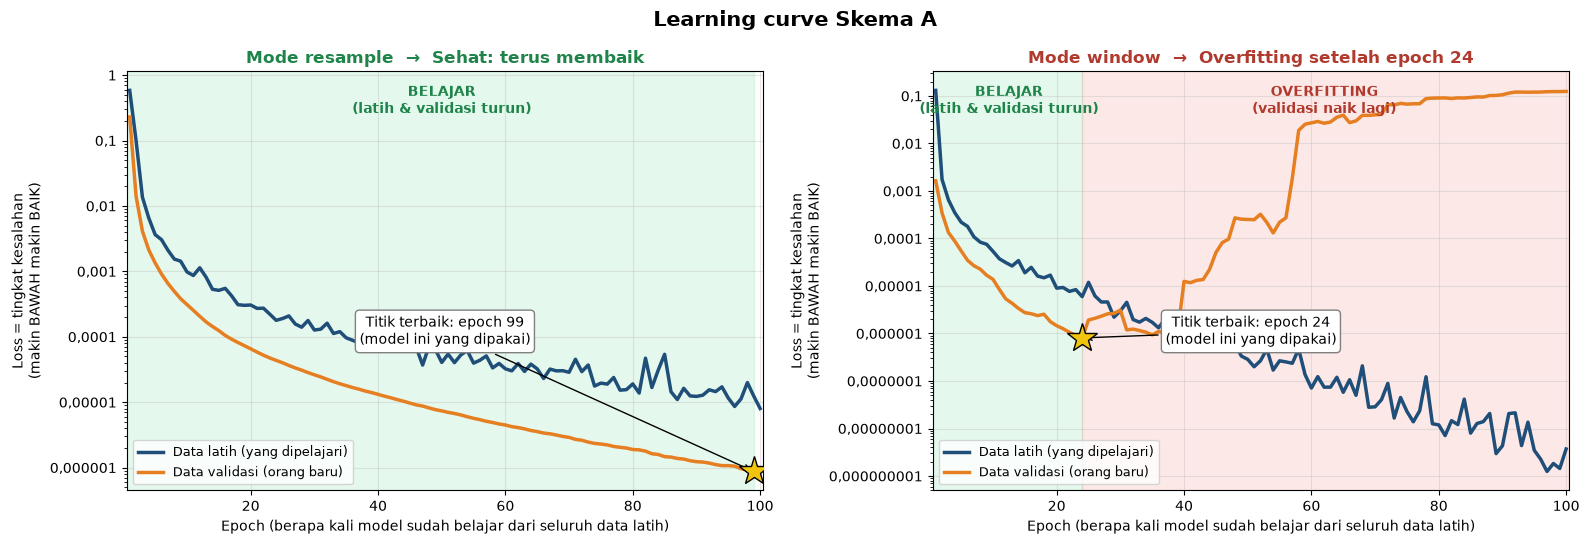

**3. Confusion matrix**

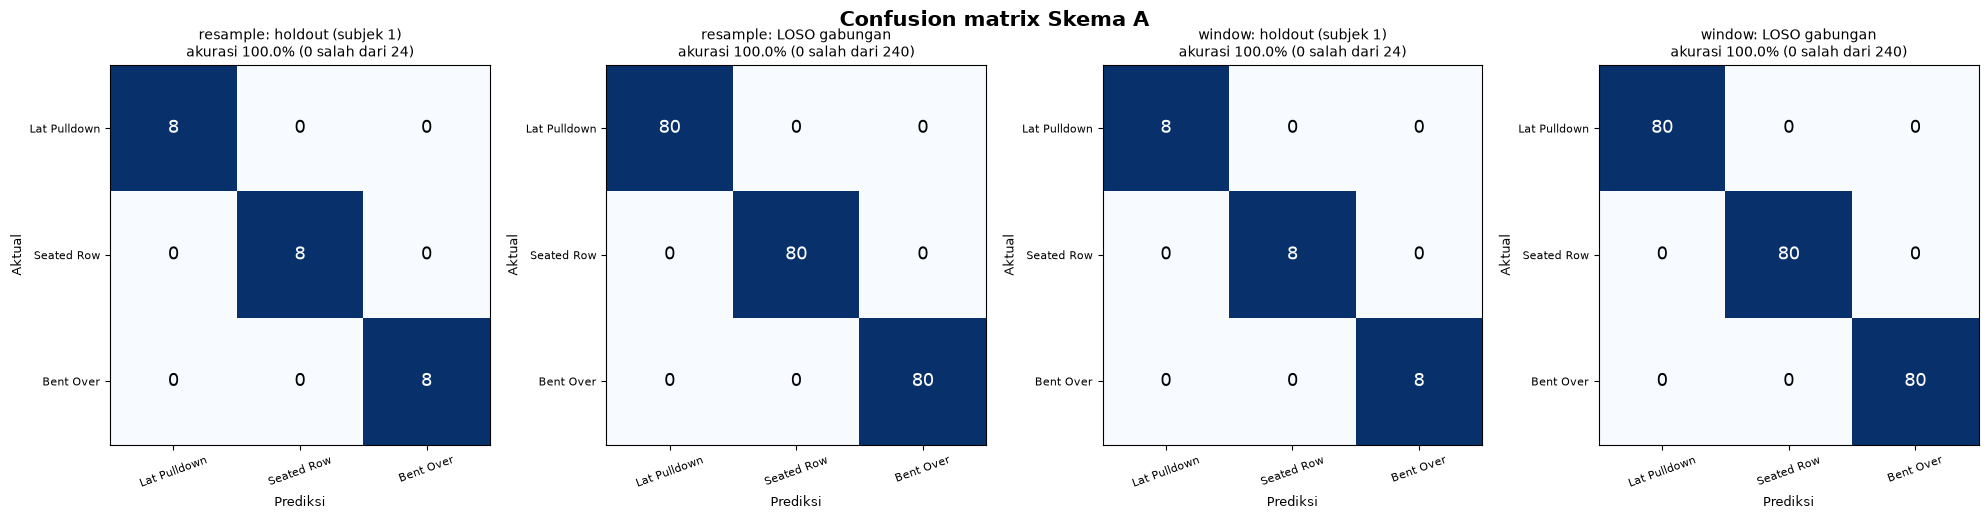

**4. Laporan per kelas (LOSO gabungan, 240 video)**

--- mode resample ---
                  precision    recall  f1-score   support

    Lat_Pulldown      1.000     1.000     1.000        80
Seated_Cable_Row      1.000     1.000     1.000        80
       Bent_over      1.000     1.000     1.000        80

        accuracy                          1.000       240
       macro avg      1.000     1.000     1.000       240
    weighted avg      1.000     1.000     1.000       240

--- mode window ---
                  precision    recall  f1-score   support

    Lat_Pulldown      1.000     1.000     1.000        80
Seated_Cable_Row      1.000     1.000     1.000        80
       Bent_over      1.000     1.000     1.000        80

        accuracy                          1.000       240
       macro avg      1.000     1.000     1.000       240
    weighted avg      1.000     1.000     1.000       240



**5. Akurasi LOSO per subjek uji**

test_subjects,[1],[2],[3],[4],[5],[6],[7],[10],"[8, 9]"
mode,,,,,,,,,
resample,100%,100%,100%,100%,100%,100%,100%,100%,100%
window,100%,100%,100%,100%,100%,100%,100%,100%,100%


In [11]:
laporan_skema("A")

### 6.2 Skema A': Koordinat ternormalisasi (26 fitur)

(x, y) dipusatkan di tengah pinggul dan dibagi panjang badan. Posisi orang di gambar dan jarak kamera tidak berpengaruh lagi, tetapi postur masih ada.

**1. Tabel metrik**

Holdout                          LOSO (rata-rata ± std)  \
         Akurasi Presisi  Recall F1-score                Akurasi   
resample  100.0%  100.0%  100.0%   100.0%          100.0% ± 0.0%   
window    100.0%  100.0%  100.0%   100.0%          100.0% ± 0.0%   

                                                            Uji tambahan  \
                Presisi         Recall       F1-score LOSO urutan diacak   
resample  100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%             100.0%   
window    100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%             100.0%   

                                
         Baseline tanpa urutan  
resample                100.0%  
window                  100.0%

**2. Learning curve (run holdout)**

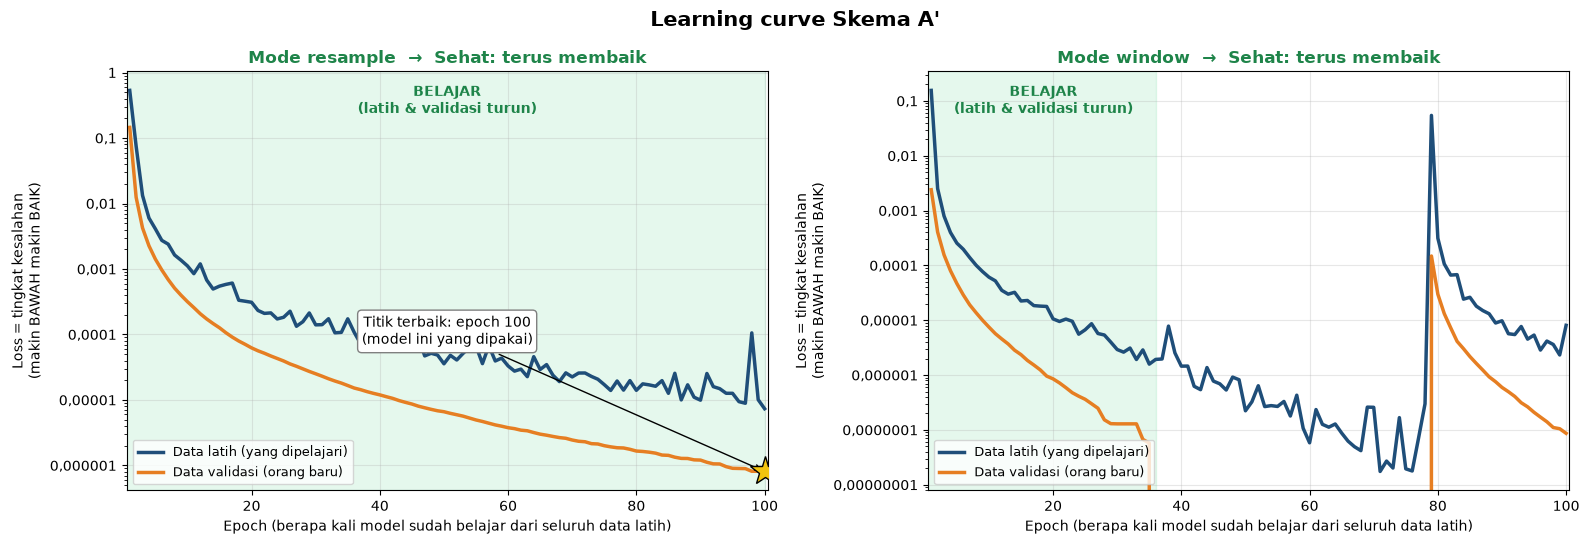

**3. Confusion matrix**

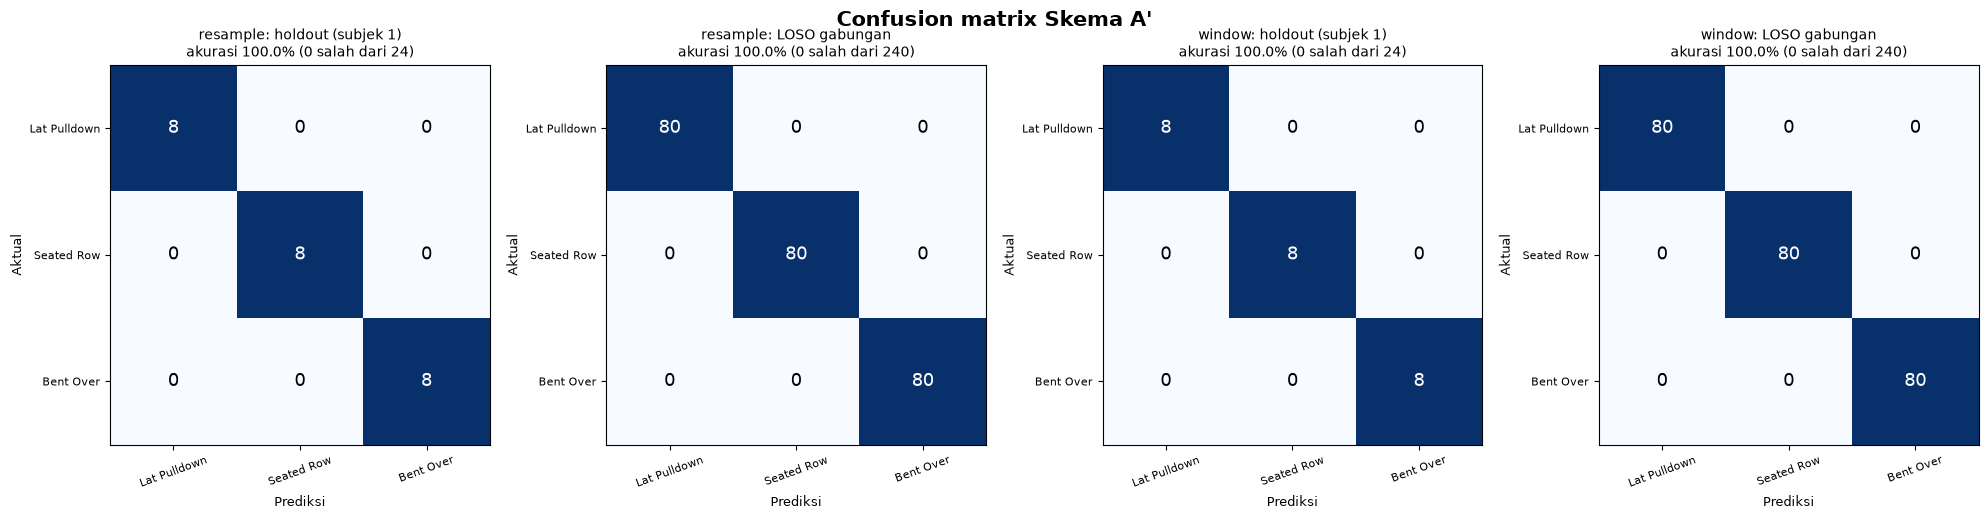

**4. Laporan per kelas (LOSO gabungan, 240 video)**

--- mode resample ---
                  precision    recall  f1-score   support

    Lat_Pulldown      1.000     1.000     1.000        80
Seated_Cable_Row      1.000     1.000     1.000        80
       Bent_over      1.000     1.000     1.000        80

        accuracy                          1.000       240
       macro avg      1.000     1.000     1.000       240
    weighted avg      1.000     1.000     1.000       240

--- mode window ---
                  precision    recall  f1-score   support

    Lat_Pulldown      1.000     1.000     1.000        80
Seated_Cable_Row      1.000     1.000     1.000        80
       Bent_over      1.000     1.000     1.000        80

        accuracy                          1.000       240
       macro avg      1.000     1.000     1.000       240
    weighted avg      1.000     1.000     1.000       240



**5. Akurasi LOSO per subjek uji**

test_subjects,[1],[2],[3],[4],[5],[6],[7],[10],"[8, 9]"
mode,,,,,,,,,
resample,100%,100%,100%,100%,100%,100%,100%,100%,100%
window,100%,100%,100%,100%,100%,100%,100%,100%,100%


In [12]:
laporan_skema("A'")

### 6.3 Skema B: Sudut sendi / Angle Directive Rules (8 fitur)

8 sudut sendi sesuai proposal. Masih memuat postur statis (misalnya sudut pinggul saat duduk vs membungkuk).

**1. Tabel metrik**

Holdout                          LOSO (rata-rata ± std)  \
         Akurasi Presisi  Recall F1-score                Akurasi   
resample  100.0%  100.0%  100.0%   100.0%           96.8% ± 9.7%   
window    100.0%  100.0%  100.0%   100.0%          96.3% ± 11.1%   

                                                            Uji tambahan  \
                Presisi         Recall       F1-score LOSO urutan diacak   
resample   98.3% ± 5.2%   96.8% ± 9.7%  96.0% ± 12.0%              74.3%   
window    94.4% ± 16.7%  96.3% ± 11.1%  95.1% ± 14.8%              89.4%   

                                
         Baseline tanpa urutan  
resample                 93.8%  
window                   93.8%

**2. Learning curve (run holdout)**

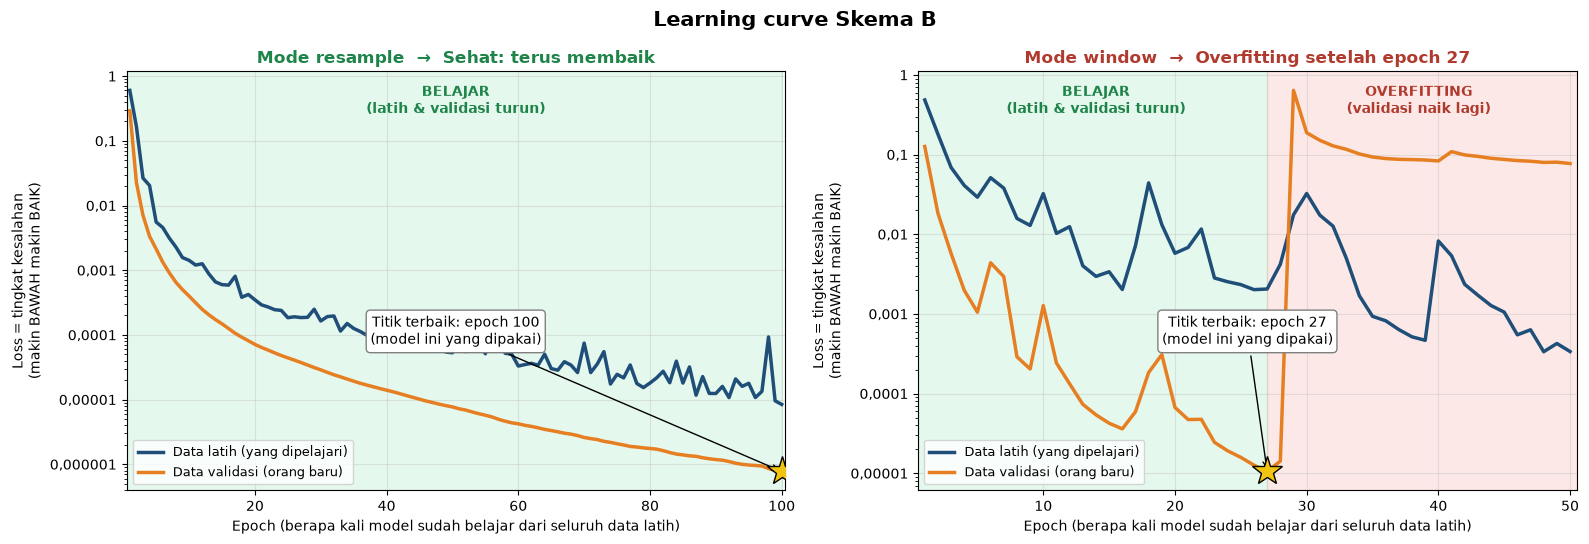

**3. Confusion matrix**

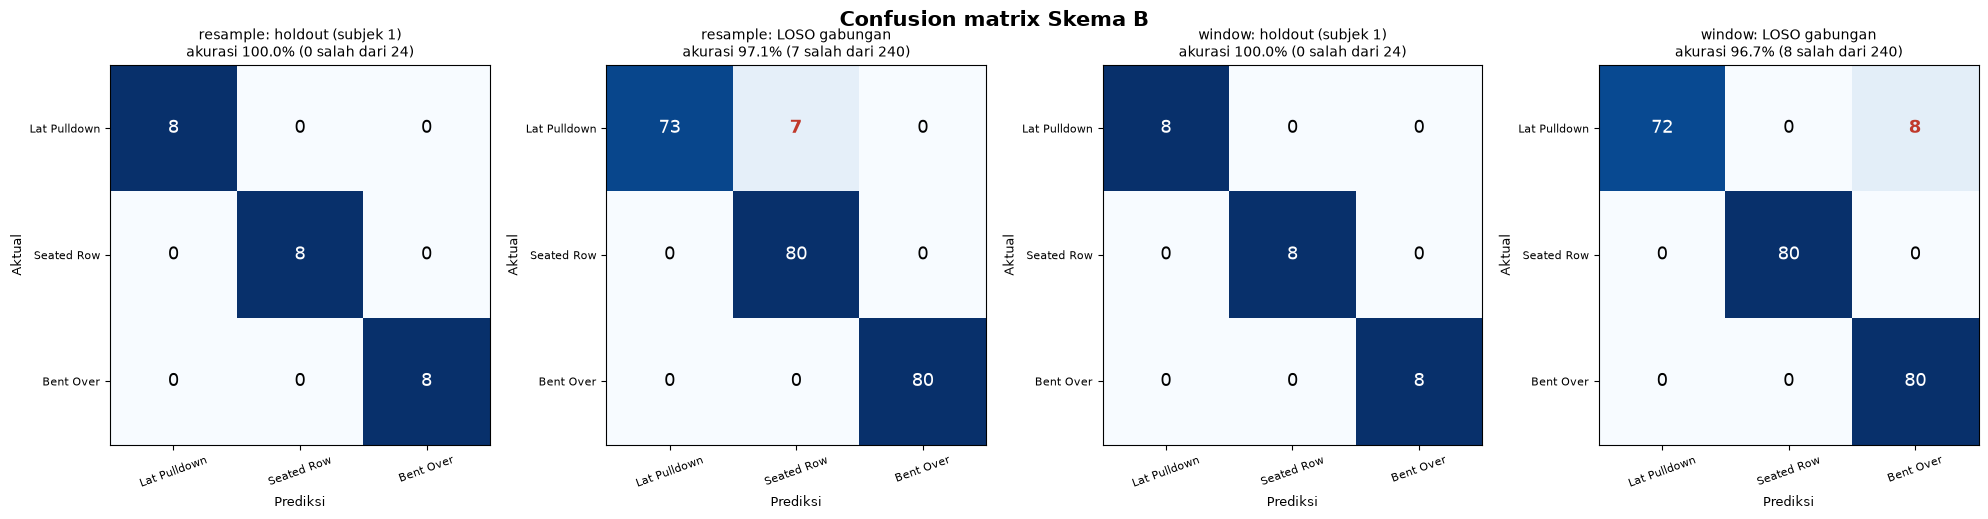

**4. Laporan per kelas (LOSO gabungan, 240 video)**

--- mode resample ---
                  precision    recall  f1-score   support

    Lat_Pulldown      1.000     0.912     0.954        80
Seated_Cable_Row      0.920     1.000     0.958        80
       Bent_over      1.000     1.000     1.000        80

        accuracy                          0.971       240
       macro avg      0.973     0.971     0.971       240
    weighted avg      0.973     0.971     0.971       240

--- mode window ---
                  precision    recall  f1-score   support

    Lat_Pulldown      1.000     0.900     0.947        80
Seated_Cable_Row      1.000     1.000     1.000        80
       Bent_over      0.909     1.000     0.952        80

        accuracy                          0.967       240
       macro avg      0.970     0.967     0.967       240
    weighted avg      0.970     0.967     0.967       240



**5. Akurasi LOSO per subjek uji**

test_subjects,[1],[2],[3],[4],[5],[6],[7],[10],"[8, 9]"
mode,,,,,,,,,
resample,100%,100%,100%,100%,100%,100%,100%,71%,100%
window,100%,100%,100%,100%,100%,100%,100%,67%,100%


In [13]:
laporan_skema("B")

### 6.4 Skema C: Gerakan sudut (16 fitur)

Sudut dikurangi rata-ratanya dalam video (postur dasar dibuang), ditambah kecepatan sudut. Model **hanya** bisa menebak dari pola gerakan.

**1. Tabel metrik**

Holdout                          LOSO (rata-rata ± std)  \
         Akurasi Presisi  Recall F1-score                Akurasi   
resample  100.0%  100.0%  100.0%   100.0%          100.0% ± 0.0%   
window    100.0%  100.0%  100.0%   100.0%           99.5% ± 1.4%   

                                                            Uji tambahan  \
                Presisi         Recall       F1-score LOSO urutan diacak   
resample  100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%              45.8%   
window     99.6% ± 1.2%   99.5% ± 1.4%   99.5% ± 1.4%              78.2%   

                                
         Baseline tanpa urutan  
resample                 92.8%  
window                   92.8%

**2. Learning curve (run holdout)**

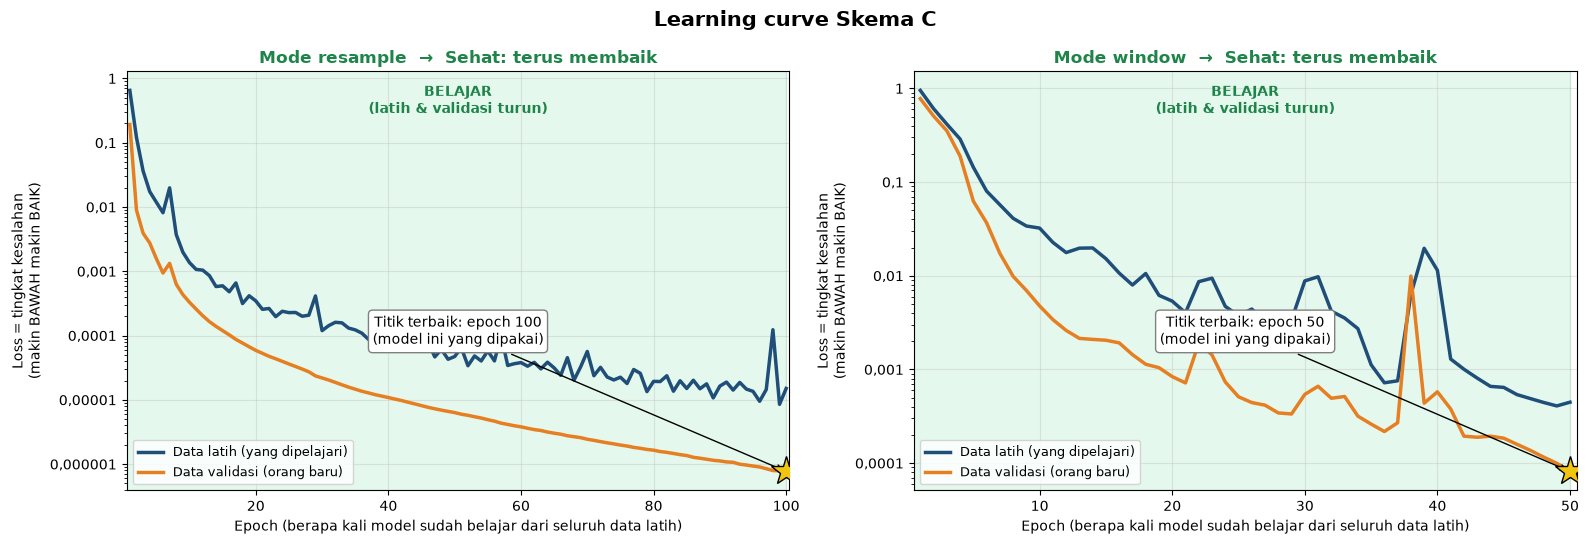

**3. Confusion matrix**

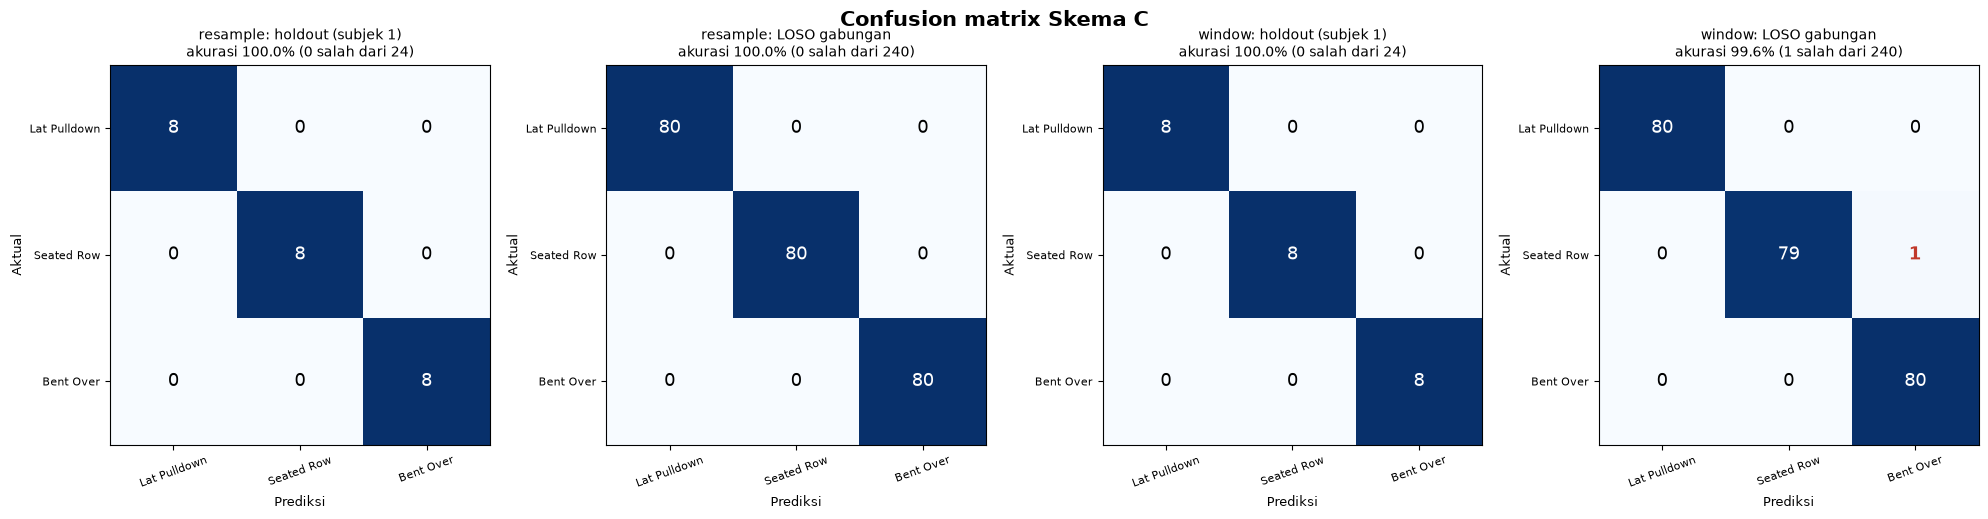

**4. Laporan per kelas (LOSO gabungan, 240 video)**

--- mode resample ---
                  precision    recall  f1-score   support

    Lat_Pulldown      1.000     1.000     1.000        80
Seated_Cable_Row      1.000     1.000     1.000        80
       Bent_over      1.000     1.000     1.000        80

        accuracy                          1.000       240
       macro avg      1.000     1.000     1.000       240
    weighted avg      1.000     1.000     1.000       240

--- mode window ---
                  precision    recall  f1-score   support

    Lat_Pulldown      1.000     1.000     1.000        80
Seated_Cable_Row      1.000     0.988     0.994        80
       Bent_over      0.988     1.000     0.994        80

        accuracy                          0.996       240
       macro avg      0.996     0.996     0.996       240
    weighted avg      0.996     0.996     0.996       240



**5. Akurasi LOSO per subjek uji**

test_subjects,[1],[2],[3],[4],[5],[6],[7],[10],"[8, 9]"
mode,,,,,,,,,
resample,100%,100%,100%,100%,100%,100%,100%,100%,100%
window,100%,100%,100%,100%,100%,96%,100%,100%,100%


In [14]:
laporan_skema("C")

### 6.5 Skema D: Gerakan koordinat (52 fitur)

Koordinat A' dikurangi rata-ratanya dalam video, ditambah kecepatan. Sama seperti C, tetapi memakai koordinat, sehingga masih terpengaruh arah kamera.

**1. Tabel metrik**

Holdout                          LOSO (rata-rata ± std)  \
         Akurasi Presisi  Recall F1-score                Akurasi   
resample  100.0%  100.0%  100.0%   100.0%           97.2% ± 8.3%   
window    100.0%  100.0%  100.0%   100.0%           98.1% ± 3.7%   

                                                         Uji tambahan  \
               Presisi        Recall      F1-score LOSO urutan diacak   
resample  98.4% ± 4.8%  97.2% ± 8.3%  96.8% ± 9.7%              42.6%   
window    98.5% ± 2.9%  98.1% ± 3.7%  98.1% ± 3.7%              93.8%   

                                
         Baseline tanpa urutan  
resample                 96.8%  
window                   96.8%

**2. Learning curve (run holdout)**

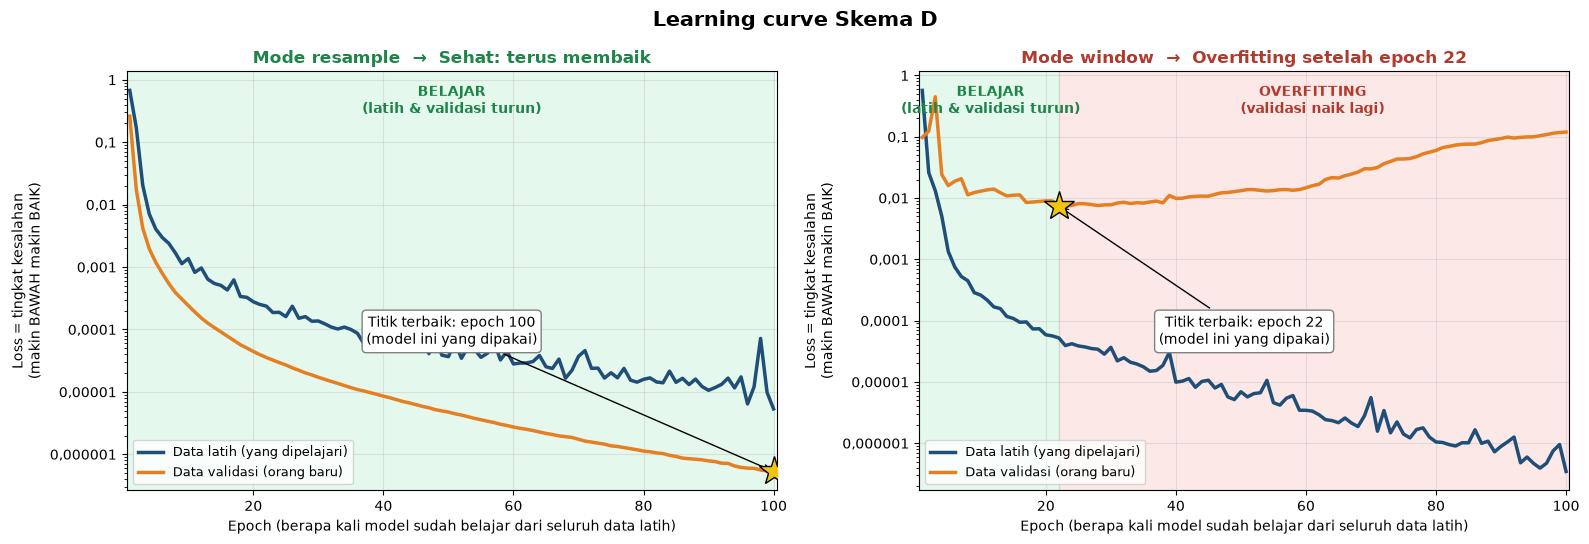

**3. Confusion matrix**

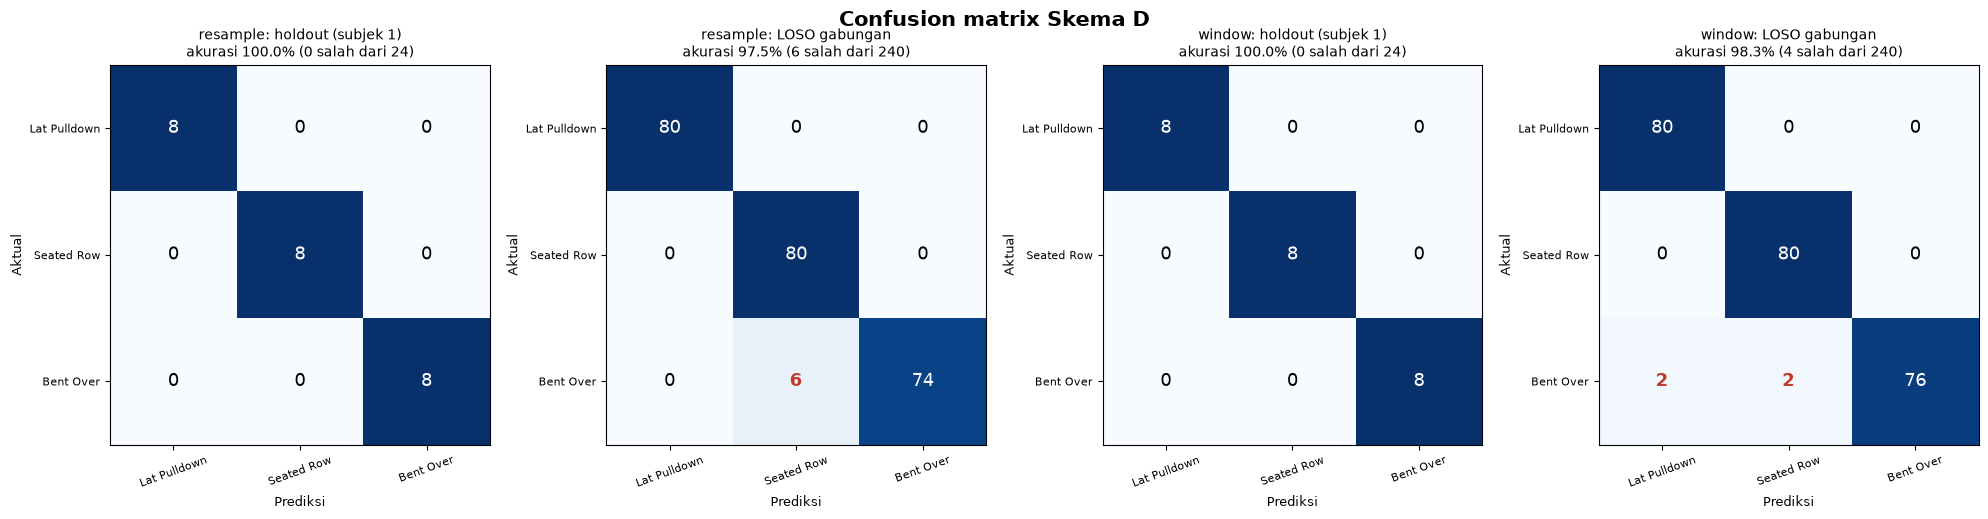

**4. Laporan per kelas (LOSO gabungan, 240 video)**

--- mode resample ---
                  precision    recall  f1-score   support

    Lat_Pulldown      1.000     1.000     1.000        80
Seated_Cable_Row      0.930     1.000     0.964        80
       Bent_over      1.000     0.925     0.961        80

        accuracy                          0.975       240
       macro avg      0.977     0.975     0.975       240
    weighted avg      0.977     0.975     0.975       240

--- mode window ---
                  precision    recall  f1-score   support

    Lat_Pulldown      0.976     1.000     0.988        80
Seated_Cable_Row      0.976     1.000     0.988        80
       Bent_over      1.000     0.950     0.974        80

        accuracy                          0.983       240
       macro avg      0.984     0.983     0.983       240
    weighted avg      0.984     0.983     0.983       240



**5. Akurasi LOSO per subjek uji**

test_subjects,[1],[2],[3],[4],[5],[6],[7],[10],"[8, 9]"
mode,,,,,,,,,
resample,100%,100%,100%,75%,100%,100%,100%,100%,100%
window,100%,100%,100%,92%,100%,92%,100%,100%,100%


In [15]:
laporan_skema("D")

## 7. Ringkasan Semua Skema

Tabel dan grafik perbandingan kelima skema (LOSO).

**💡 Penjelasan kode**

- Tabel `summary`: satu baris per skema × mode, berisi rata-rata dan standar deviasi 4 metrik LOSO, akurasi holdout, akurasi saat urutan diacak, dan baseline. Disimpan ke `summary.csv`.
- Grafik kiri/kanan: 4 metrik per skema untuk mode resample/window. Garis hitam kecil = standar deviasi antar subjek.

LOSO Akurasi   LOSO Presisi    LOSO Recall  LOSO F1-score  \
scheme mode                                                                   
A      resample  100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%   
       window    100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%   
A'     resample  100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%   
       window    100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%   
B      resample   96.8% ± 9.7%   98.3% ± 5.2%   96.8% ± 9.7%  96.0% ± 12.0%   
       window    96.3% ± 11.1%  94.4% ± 16.7%  96.3% ± 11.1%  95.1% ± 14.8%   
C      resample  100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%  100.0% ± 0.0%   
       window     99.5% ± 1.4%   99.6% ± 1.2%   99.5% ± 1.4%   99.5% ± 1.4%   
D      resample   97.2% ± 8.3%   98.4% ± 4.8%   97.2% ± 8.3%   96.8% ± 9.7%   
       window     98.1% ± 3.7%   98.5% ± 2.9%   98.1% ± 3.7%   98.1% ± 3.7%   

                Urutan diacak Baseline  
scheme mode                             
A      resample        100.0%   100.0%  
       window          100.0%   100.0%  
A'     resample        100.0%   100.0%  
       window          100.0%   100.0%  
B      resample         74.3%    93.8%  
       window           89.4%    93.8%  
C      resample         45.8%    92.8%  
       window           78.2%    92.8%  
D      resample         42.6%    96.8%  
       window           93.8%    96.8%

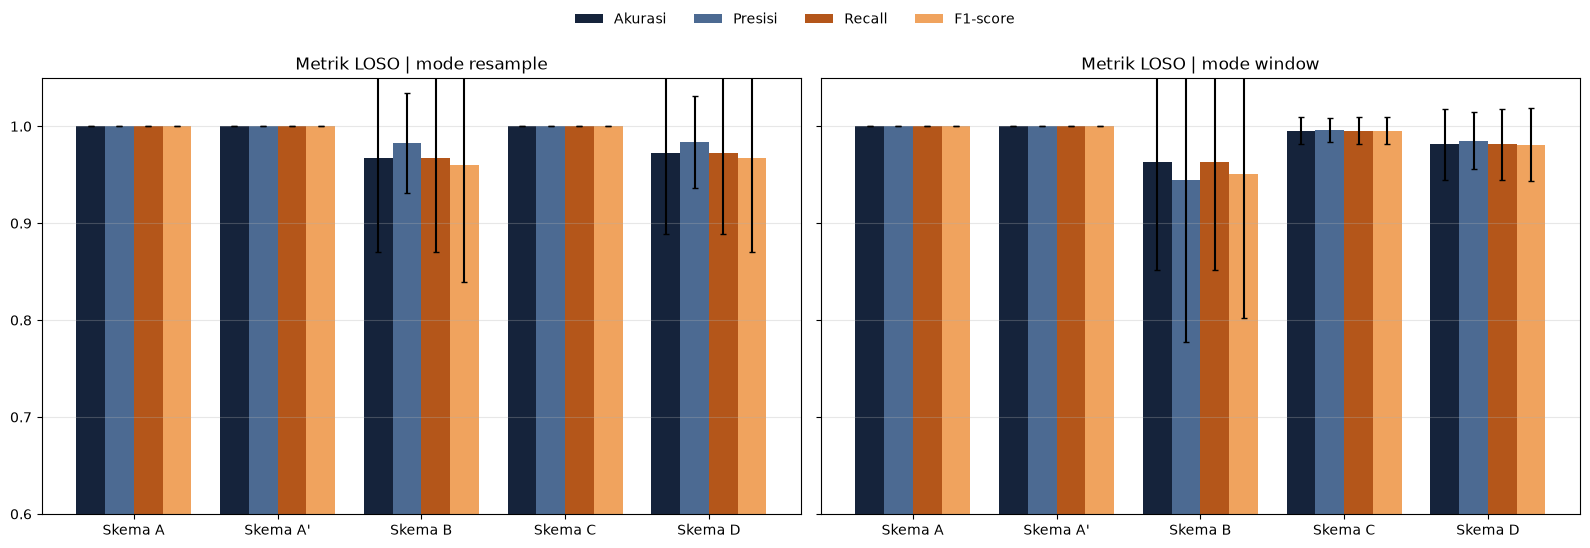

In [16]:
loso = runs[runs.fold.str.startswith("loso")]
agg = loso.groupby(["scheme", "mode"], sort=False)[METRICS + ["shuffled_accuracy"]].agg(["mean", "std"])
summary = pd.DataFrame(index=agg.index)
for k in METRICS:
    summary[f"loso_{k}_mean"], summary[f"loso_{k}_std"] = agg[(k, "mean")], agg[(k, "std")]
summary["loso_shuffled_accuracy"] = agg[("shuffled_accuracy", "mean")]
summary["holdout_accuracy"] = runs[runs.fold == "holdout"].set_index(["scheme", "mode"]).accuracy
summary["baseline_loso_accuracy"] = summary.index.get_level_values("scheme").map(
    baseline[baseline.fold.str.startswith("loso")].groupby("scheme").accuracy.mean())
summary.to_csv(OUT_DIR / "summary.csv")

show = pd.DataFrame(index=summary.index)
for k in METRICS:
    show[f"LOSO {METRIC_ID[k]}"] = [f"{a:.1%} ± {b:.1%}" for a, b in zip(summary[f"loso_{k}_mean"], summary[f"loso_{k}_std"])]
show["Urutan diacak"] = summary.loso_shuffled_accuracy.map("{:.1%}".format)
show["Baseline"] = summary.baseline_loso_accuracy.map("{:.1%}".format)
display(show)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
colors = ["#15233B", "#4C6A92", "#B4561A", "#F0A35E"]
for ax, mode in zip(axes, SEQ_MODES):
    x = np.arange(len(SCHEMES))
    for i, k in enumerate(METRICS):
        ax.bar(x + (i - 1.5) * 0.2, [summary.loc[(s, mode), f"loso_{k}_mean"] for s in SCHEMES], 0.2,
               yerr=[summary.loc[(s, mode), f"loso_{k}_std"] for s in SCHEMES], capsize=2, color=colors[i], label=METRIC_ID[k])
    ax.set_xticks(x, [f"Skema {s}" for s in SCHEMES])
    ax.set_ylim(0.6, 1.05)
    ax.set_title(f"Metrik LOSO | mode {mode}")
    ax.grid(axis="y", alpha=0.3)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=4, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.savefig(FIG_DIR / "ringkasan_metrik.png", dpi=150)
plt.show()

**💡 Penjelasan kode**

Grafik pembuktian **apakah model memakai urutan gerakan**, dengan tiga batang per skema:
- **LSTM (urutan asli)**: hasil normal.
- **LSTM (urutan diacak)**: frame data uji dikocok. Jika turun jauh, model bergantung pada urutan gerakan.
- **Baseline tanpa urutan**: model yang sejak awal tidak melihat urutan.
- Garis titik-titik = tebakan acak (33%).

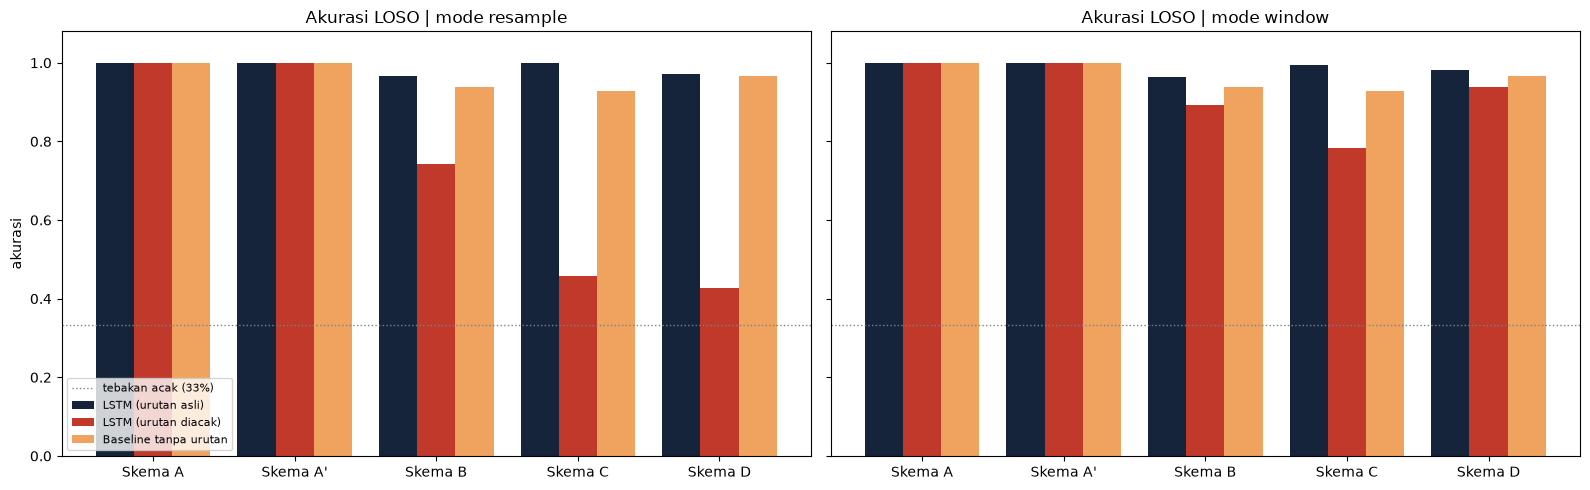

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, mode in zip(axes, SEQ_MODES):
    s = summary.xs(mode, level="mode").reindex(SCHEMES)
    x = np.arange(len(SCHEMES))
    ax.bar(x - 0.27, s.loso_accuracy_mean, 0.27, label="LSTM (urutan asli)", color="#15233B")
    ax.bar(x, s.loso_shuffled_accuracy, 0.27, label="LSTM (urutan diacak)", color="#C0392B")
    ax.bar(x + 0.27, s.baseline_loso_accuracy, 0.27, label="Baseline tanpa urutan", color="#F0A35E")
    ax.axhline(1 / 3, color="gray", ls=":", lw=1, label="tebakan acak (33%)")
    ax.set_xticks(x, [f"Skema {sc}" for sc in SCHEMES])
    ax.set_ylim(0, 1.08)
    ax.set_title(f"Akurasi LOSO | mode {mode}")
axes[0].set_ylabel("akurasi")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "uji_urutan_dan_baseline.png", dpi=150)
plt.show()

## 8. Perbandingan Tanpa vs Dengan Augmentasi

Membandingkan hasil notebook ini dengan `results/tanpa_augmentasi/`. Yang dilihat:
- **Metrik LOSO**: apakah augmentasi menaikkan akurasi/F1 atau membuatnya lebih stabil (std lebih kecil)?
- **Urutan diacak**: apakah model lebih bergantung pada urutan gerakan?
- **Overfitting**: kenaikan val_loss dari titik terendah sampai akhir training. Makin besar, makin menghafal setelah titik terbaiknya.

**💡 Penjelasan kode**

- Membaca `summary.csv` dan `histories.json` dari notebook 2, lalu menggabungkannya dengan hasil notebook ini.
- `selisih` = dengan − tanpa augmentasi (dalam poin persen). Positif = augmentasi membantu.
- `Kenaikan val_loss` = val_loss epoch terakhir − val_loss terendah. 0 = tidak naik sama sekali (sehat). Makin besar, makin jauh model "memburuk" setelah titik terbaiknya (overfitting atau tidak stabil).
- Selisih 1 poin ≈ 2–3 video dari 240. Selisih sekecil itu belum tentu bermakna.

In [22]:
BASE_DIR = ROOT / "results" / "tanpa_augmentasi"
sum_no = pd.read_csv(BASE_DIR / "summary.csv").set_index(["scheme", "mode"])
hist_no = json.loads((BASE_DIR / "histories.json").read_text())


def val_loss_rise(hist):
    # Kenaikan val_loss dari titik terendah sampai epoch terakhir (0 = tidak naik sama sekali)
    return hist["val_loss"][-1] - min(hist["val_loss"])


comp = pd.DataFrame(index=summary.index)
for k, name in [("accuracy", "Akurasi"), ("f1", "F1")]:
    comp[f"{name} tanpa"] = sum_no[f"loso_{k}_mean"]
    comp[f"{name} dengan"] = summary[f"loso_{k}_mean"]
    comp[f"{name} selisih (poin)"] = (comp[f"{name} dengan"] - comp[f"{name} tanpa"]) * 100
comp["Std akurasi tanpa"] = sum_no.loso_accuracy_std
comp["Std akurasi dengan"] = summary.loso_accuracy_std
comp["Urutan diacak tanpa"] = sum_no.loso_shuffled_accuracy
comp["Urutan diacak dengan"] = summary.loso_shuffled_accuracy
comp["Kenaikan val_loss tanpa"] = [val_loss_rise(hist_no[f"{s}|{m}"]) for s, m in comp.index]
comp["Kenaikan val_loss dengan"] = [val_loss_rise(histories[f"{s}|{m}"]) for s, m in comp.index]
comp.to_csv(OUT_DIR / "perbandingan_augmentasi.csv")

pct_cols = [c for c in comp.columns if "tanpa" in c or "dengan" in c]
pct_cols = [c for c in pct_cols if "val_loss" not in c]
comp.style.format({**{c: "{:.1%}" for c in pct_cols}, **{c: "{:+.1f}" for c in comp.columns if "selisih" in c},
                   **{c: "{:.4f}" for c in comp.columns if "val_loss" in c}})

**💡 Penjelasan kode**

Learning curve **val_loss** tanpa (garis putus-putus) vs dengan augmentasi (garis penuh) untuk setiap skema. Jika garis putus-putus naik lagi setelah beberapa epoch sementara garis penuh terus turun, berarti augmentasi **mencegah overfitting**.

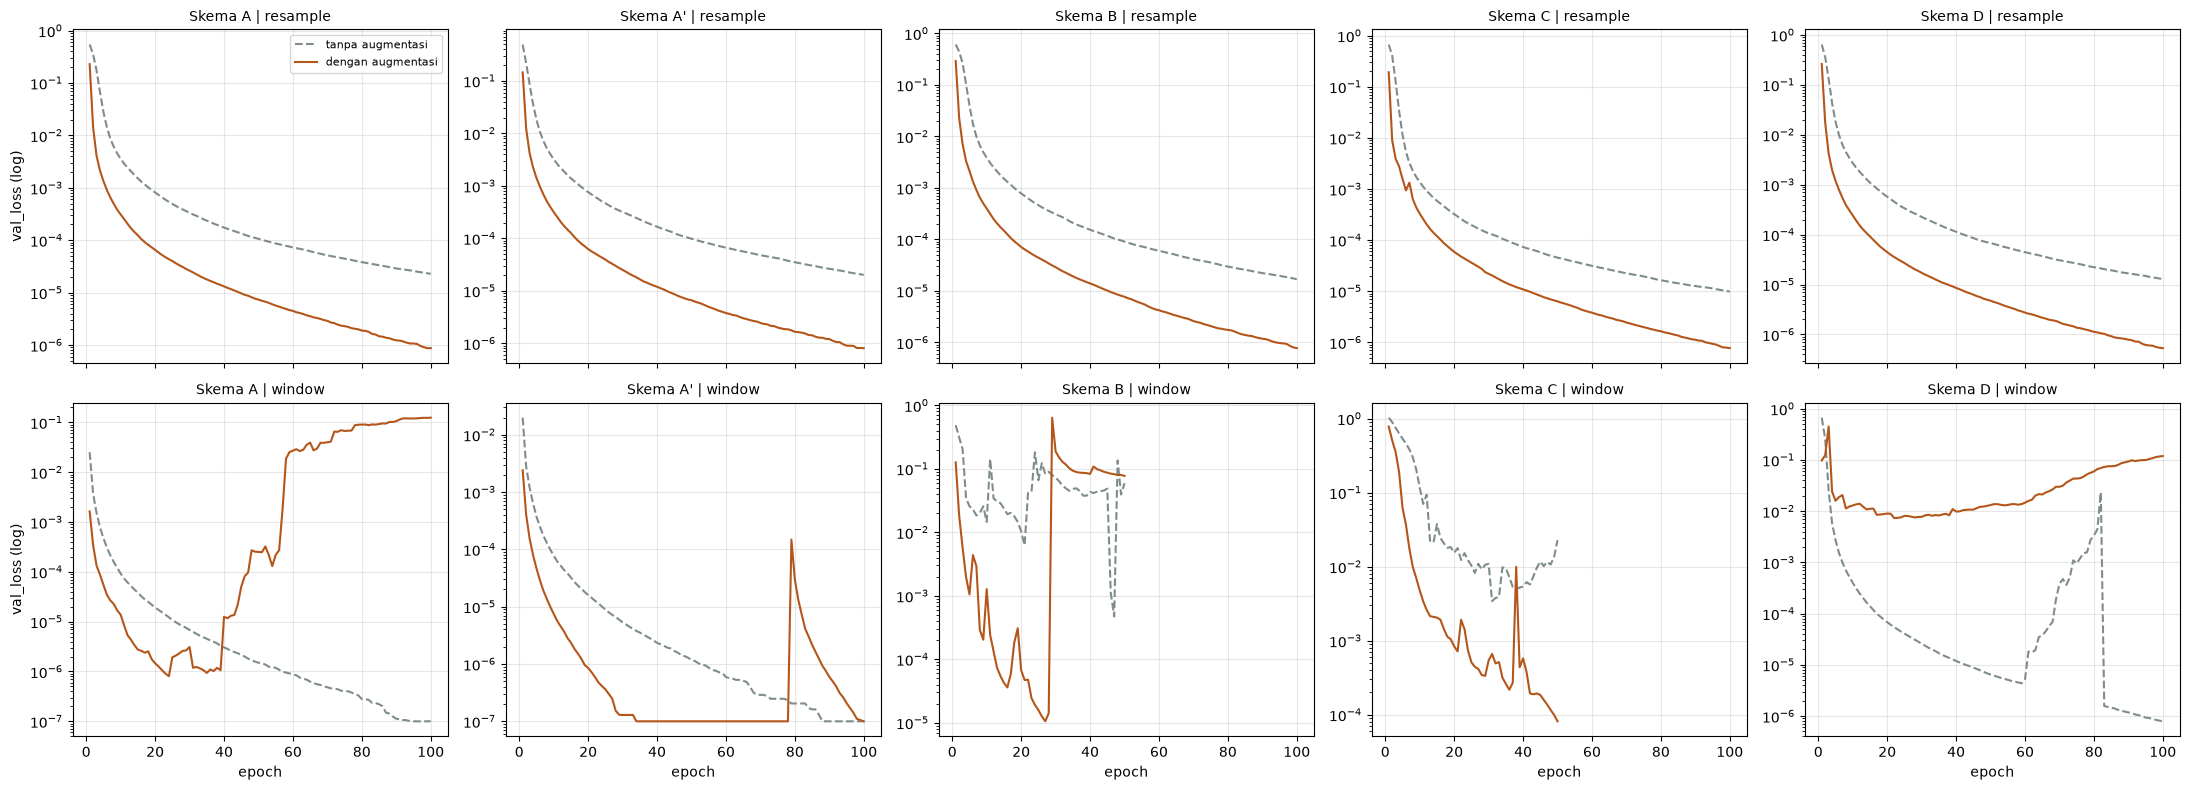

In [23]:
fig, axes = plt.subplots(2, len(SCHEMES), figsize=(22, 8), sharex=True)
for i, mode in enumerate(SEQ_MODES):
    for j, s in enumerate(SCHEMES):
        ax = axes[i, j]
        v_no = np.maximum(hist_no[f"{s}|{mode}"]["val_loss"], 1e-7)       # loss 0 dibatasi 1e-7 (skala log)
        v_aug = np.maximum(histories[f"{s}|{mode}"]["val_loss"], 1e-7)
        ax.plot(range(1, len(v_no) + 1), v_no, ls="--", color="#7F8C8D", label="tanpa augmentasi")
        ax.plot(range(1, len(v_aug) + 1), v_aug, color="#B4561A", label="dengan augmentasi")
        ax.set_yscale("log")
        ax.set_title(f"Skema {s} | {mode}", fontsize=10)
        ax.grid(alpha=0.3)
    axes[i, 0].set_ylabel("val_loss (log)")
for ax in axes[-1]:
    ax.set_xlabel("epoch")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "val_loss_tanpa_vs_dengan.png", dpi=150)
plt.show()

### Cara membaca hasil

| Pola | Artinya |
|---|---|
| Baseline tinggi (≈ LSTM) | kelas bisa ditebak dari postur saja, urutan gerakan tidak diperlukan |
| Baseline C/D rendah, LSTM C/D tinggi | model membedakan kelas dari **pola gerakan** |
| Akurasi turun jauh saat urutan diacak | model memanfaatkan urutan waktu (kontribusi LSTM) |
| Std LOSO besar / ada subjek dengan akurasi rendah | hasil bergantung pada orangnya; lihat tabel per subjek |
| Loss validasi naik lagi, loss latih terus turun | overfitting; checkpoint val_loss terendah mencegah bobot yang buruk dipakai |
| Recall rendah pada satu kelas | banyak video kelas itu yang tidak dikenali |
| Presisi rendah pada satu kelas | model terlalu sering menebak kelas itu |